# Analysis of Atmospheric River Mobility Data
The goal of this notebook is to perform an analysis of daily cell-phone trajectory statistics for the 30 March 2024 Atmospheric River event in southern California.

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm
from scipy.stats import ks_2samp, bootstrap, ecdf, percentileofscore
from scipy.ndimage import gaussian_filter
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, LogNorm
import shapefile
import matplotlib.ticker as ticker

import json
import urllib3
import xarray as xr
%matplotlib inline

## Data Loading
We will load data from our analysis pipeline and mapping data to aid in visualizing different aggregations of the statistics.
First we will load home locations estimated from the full trajectory data.

In [3]:
home_loc_df = pd.read_parquet("/glade/work/ggantos/cat-rain/notebooks/home_loc_by_row_group_counties.parquet")


In [4]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))
ar_file_dates = [ar_file.split("/")[-1].split("_")[1] for ar_file in ar_files]
all_dates = pd.DatetimeIndex(ar_file_dates)
sat_ids = np.where((all_dates.dayofweek == 5) & (all_dates.year == 2024))[0][:-2]
sat_datetimes = all_dates[sat_ids]
sat_dates = sat_datetimes.strftime("%Y-%m-%d")
print(sat_dates)
print(sat_ids)

Index(['2024-03-16', '2024-03-23', '2024-03-30', '2024-04-06', '2024-04-13'], dtype='object')
[47 54 61 68 75]


In [5]:
# Load county shape file
county_shapes = shapefile.Reader("/glade/campaign/cisl/aiml/cat_flood/ancillary_data/county_shapes/county_shapes").shapes()
# Load zip code shapes
with open("/glade/work/cbecker/california_zip.geojson") as cal_zip_file:
    cal_zips = json.load(cal_zip_file)
zip_codes = np.array([cz["properties"]["ZIP_CODE"] for cz in cal_zips["features"]])
# Load Flash Flood Warning Polygons
req = urllib3.request("GET", "https://mesonet.agron.iastate.edu/api/1/cow.json?wfo=LOX&begints=2024-03-28T12:00:00Z&enable_shared_border=1&endts=2024-03-31T12:00:00Z&hailsize=1&wind=58&phenomena=FF&lsrbuffer=15&warningbuffer=1")
ffws = json.loads(req.data)
rain_ds = xr.open_dataset("/glade/campaign/cisl/aiml/cat_flood/mrms/raw/mrms_precip_daily.nc")
rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30").max() / 25.4

<xarray.DataArray 'MultiSensor_QPE_01H_Pass2_00.00_sum' ()>
array(4.93700787)
Coordinates:
    time     datetime64[ns] 2024-03-30

In [22]:
zip_counts = home_loc_df.groupby("zipcode").count()["duration"]

In [23]:
zip_counts

zipcode
90001    47226
90002    63652
90003    54798
90004    58545
90005    35337
         ...  
93551    69612
93552    44604
93553     1014
93563      723
93591     6299
Name: duration, Length: 345, dtype: int64

In [6]:
with open("NHS.geojson") as cal_hwy_file:
    cal_hwy = json.load(cal_hwy_file)

In [11]:
cal_hwy["features"][0]["properties"]

{'OBJECTID': 1,
 'RouteID': 'SHS_004._P',
 'FromARMeasure': 35.8830601,
 'ToARMeasure': 61.9455806,
 'NHS_TYPE': 'M21PA',
 'GlobalID': '{A78935ED-19BF-4579-BA1C-688876FEA2E6}',
 'Shape_Length': 0.46405903605806353}

In [7]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))
ar_files = list(np.array(ar_files)[sat_ids])
ar_file = ar_files[0]
ar_date = ar_file.split("/")[-1].split("_")[1]
metric = 'distance_straight_line'
meta_cols = ["uid", "duration",	"lat_home",	"lng_home", "zipcode", "row_group",	"county"]
cols =  meta_cols + [metric]
df_0 = pd.read_parquet(ar_file, columns=cols)
df_0 = df_0.set_index("uid")
df_joined = df_0
new_col = ar_date
df_joined = df_joined.rename(columns={metric: new_col})
metric_cols = [new_col]
for ar_file in tqdm(ar_files[1:]):
    ar_date = ar_file.split("/")[-1].split("_")[1]
    df_l = pd.read_parquet(ar_file, columns=cols)
    df_l = df_l.set_index("uid")
    df_joined = df_joined.join(df_l.loc[:, [metric]], how="outer")
    new_rows = df_joined.index[np.isnan(df_joined["lat_home"])]

    df_joined.loc[new_rows, meta_cols[1:]] = df_l.loc[new_rows, meta_cols[1:]]
    new_col = f"{ar_date}"
    df_joined = df_joined.rename(columns={metric: f"{ar_date}"})
    metric_cols.append(new_col)

100%|██████████| 4/4 [00:15<00:00,  3.78s/it]


Now that data are loaded, we filter out people who do not have a distance traveled statistic for all Saturdays in our analysis.

In [8]:
df_joined_sub = df_joined.dropna()

In [9]:
m_date = "2024-03-30"
daily_ar_data = pd.read_parquet(f'/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_{m_date}_PST_chunked.parquet')
daily_ar_data = daily_ar_data.set_index("uid")
ar_cols = ["num_stops", "number_of_visits", "FFW", "precip_max", "precip_sum", "streamflow_max", "streamflow_sum"]
df_joined_ar = df_joined_sub.join(daily_ar_data[ar_cols])

<Axes: >

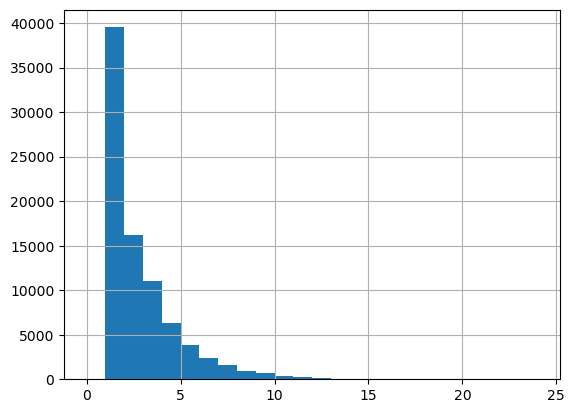

In [10]:
df_joined_ar["num_stops"].hist(bins=np.arange(25))


## Statistical Calculations
Travel patterns vary significantly from person to person. To control for this variation, we calculate the percentile of the total distance traveled for the Saturday of the AR event relative to the 2 Saturdays before and the 2 Saturdays after. While we have acquired more data than these Saturdays, our dataset contains fewer contiguous records of paired daily cell phone trajectories as the time window is expanded. We have to trade off sample size for data fidelity.

In [11]:
metric_array = df_joined_ar[metric_cols].values.astype(np.float64)
user_ar_percentile = np.zeros(df_joined_ar.shape[0])
for i in tqdm(range(metric_array.shape[0])):
    user_ar_percentile[i] = percentileofscore(metric_array[i, [True, True, False, True, True]], 
                                              metric_array[i, 2], nan_policy="omit")
df_joined_ar[metric + "_percentile"] = user_ar_percentile

100%|██████████| 83503/83503 [00:01<00:00, 45438.98it/s]


In [52]:
df_joined_ar

,duration,lat_home,lng_home,zipcode,row_group,county,2024-03-16,2024-03-23,2024-03-30,2024-04-06,2024-04-13,num_stops,number_of_visits,FFW,precip_max,precip_sum,streamflow_max,streamflow_sum,distance_straight_line_percentile
uid,,,,,,,,,,,,,,,,,,,
000410d2eb6bcdd8e3a21e7d55ba32a556e023e8b70915b916eb6dd8e5c9dd21,4 days 04:37:26,34.049355,-117.779315,91766,4.0,LA,0.257756,0.114315,0.206573,0.191767,0.153010,1,41,False,7.5,44.1,1.0,8.0,75.0
00052904e43d75374b6b7ce6e7dfd0bf89c70d14f403a6b2bd3ed473621c24b5,5 days 03:49:50,34.263945,-119.219457,93003,6.0,VE,2.082497,0.522170,0.782543,0.515882,1.947978,1,5,False,5.9,26.8,1.1,6.2,50.0
0005db95f4b81827bbafc84d2c4f20197b6c7af3e7ecd2deb44c70be2b29f92d,13 days 10:11:13,33.983781,-118.201797,90255,6.0,LA,0.593729,0.360012,0.164533,0.174827,0.282026,1,15,True,5.5,34.5,1.2,11.4,0.0
0005fac987ebae8b8adc1de113207c9da33361abf6b88b909f01f9808690d5d1,14 days 06:35:28,34.276958,-118.413451,91331,6.0,LA,141.941402,64.039535,18.626049,22.376177,77.870090,3,28,False,8.4,36.3,2.3,14.5,0.0
00065ed65abecbf863abdd49ec8e87100128c416509dca2f8b4aa544ba108cf0,22 days 05:43:02,33.801420,-118.111820,90815,7.0,LA,130.461157,139.708419,8.867619,4.209708,231.804435,2,34,False,11.6,46.6,0.9,8.4,25.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fffe46ca8723ff880b80e4a2dff820dfb7b7ce9aa45e53e9b06cb12a859a3685,0 days 23:45:24,33.976347,-118.253574,90001,75015.0,LA,0.129720,0.095455,0.026275,1377.595087,0.039351,1,5,True,4.9,32.6,0.8,6.8,0.0
fffe68467d281000b4b4a4d22fabfd43f58683acdd65a7dc9f3d1c94931f2b53,1 days 00:30:13,33.904062,-118.143072,90242,75015.0,LA,0.519980,0.370353,0.010191,0.080458,0.285083,1,10,False,5.4,42.5,0.7,6.6,0.0
fffea50b3f97f128692ab729cfe29053043805294515ef1299ae645434b8de22,14 days 16:47:30,34.575502,-118.032679,93552,75016.0,LA,141.766198,0.595804,75.935413,0.178912,0.074233,1,32,False,5.9,32.9,0.7,5.8,75.0


(array([23837., 16531., 14182., 14711., 14242.]),
 array([  0.,  20.,  40.,  60.,  80., 100.]),
 <BarContainer object of 5 artists>)

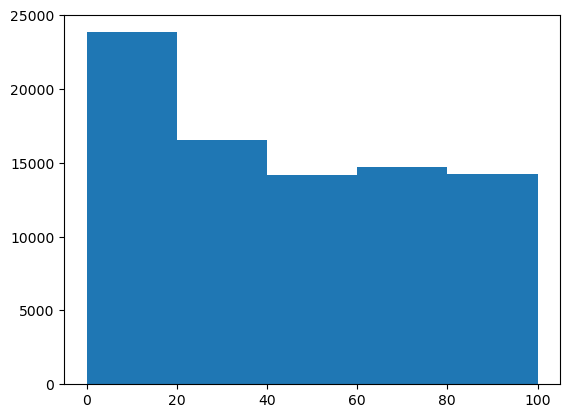

In [12]:
plt.hist(user_ar_percentile, bins=np.arange(0, 120,20))


(array([0.01423256, 0.00988935, 0.00849746, 0.00880233, 0.0085783 ]),
 array([  0.,  20.,  40.,  60.,  80., 100.]),
 [<matplotlib.patches.Polygon at 0x1546f49fed10>])

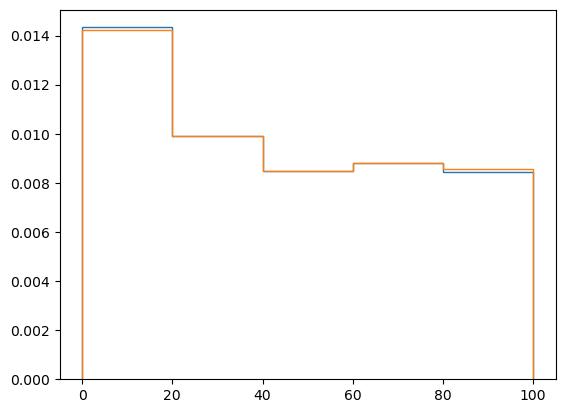

In [53]:
plt.hist(df_joined_ar.loc[df_joined_ar["FFW"], metric + "_percentile"], np.arange(0, 120, 20), histtype="step", density=True)
plt.hist(df_joined_ar.loc[~df_joined_ar["FFW"], metric + "_percentile"], np.arange(0, 120, 20), histtype="step", density=True)

(array([0.01298544, 0.01036408, 0.00910194, 0.00883495, 0.00871359]),
 array([  0.,  20.,  40.,  60.,  80., 100.]),
 [<matplotlib.patches.Polygon at 0x1546f480b940>])

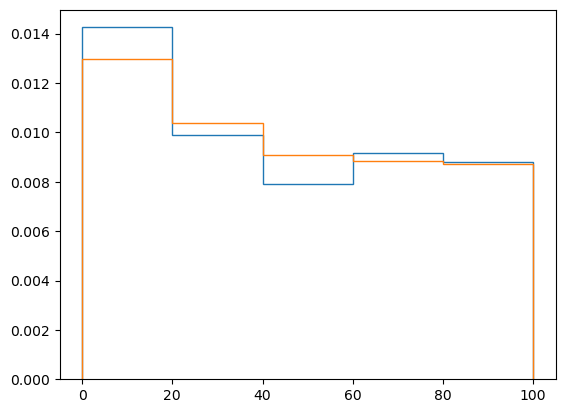

In [49]:
pos_idx =  (df_joined_ar["precip_sum"] >= 35) & (df_joined_ar["county"] == "SB")
neg_idx =  (df_joined_ar["precip_sum"] < 35) & (df_joined_ar["county"] == "SB")
plt.hist(df_joined_ar.loc[pos_idx, metric + "_percentile"], np.arange(0, 120, 20), histtype="step", density=True, cumulative=False)
plt.hist(df_joined_ar.loc[neg_idx, metric + "_percentile"], np.arange(0, 120, 20), histtype="step", density=True, cumulative=False)

In [ ]:
# Flash Flood Warning
# County Name | Home In FFW? | Relative Freq in Lowest Percentile | 
#                

In [63]:
for county in ["LA", "SB", "VE"]:
    pos_idx =  (df_joined_ar["FFW"]) & (df_joined_ar["county"] == county)
    neg_idx =  (~df_joined_ar["FFW"]) & (df_joined_ar["county"] == county)
    print(np.count_nonzero(df_joined_ar.loc[pos_idx, metric + "_percentile"] < 25) / pos_idx.sum(), np.count_nonzero(df_joined_ar.loc[neg_idx, metric + "_percentile"] == 0.0) / neg_idx.sum())

0.28744652793412884 0.2858125875500725
0.2646420824295011 0.26933962264150946
0.2802547770700637 0.28291480873034497


In [64]:
from scipy.stats import permutation_test

In [75]:
np.unique(df_joined_ar.loc[pos_idx, metric + "_percentile"])

array([  0.,  25.,  50.,  75., 100.])

In [105]:
def rank_difference(pos_sample, neg_sample):
    return np.count_nonzero(pos_sample) / pos_sample.size - np.count_nonzero(neg_sample) / neg_sample.size  
for county in ["SB", "VE", "LA"]:
    pos_idx =  (df_joined_ar["FFW"]) & (df_joined_ar["county"] == county)
    neg_idx =  (~df_joined_ar["FFW"]) & (df_joined_ar["county"] == county)
    pos_sample = df_joined_ar.loc[pos_idx, metric + "_percentile"].values < 25
    neg_sample = df_joined_ar.loc[neg_idx, metric + "_percentile"].values < 25
    per_res = permutation_test([pos_sample, neg_sample],
                 rank_difference, n_resamples=9999)
    pos_freq = np.count_nonzero(pos_sample) / pos_sample.size
    neg_freq = np.count_nonzero(neg_sample) / neg_sample.size
    print(county, pos_idx.sum(), neg_idx.sum(), f"{pos_freq:0.3f}", f"{neg_freq:0.3f}", 
          f"{per_res.statistic:0.5f}", f"{per_res.pvalue:0.4f}\\\\", sep="&")
                  

SB&922&2120&0.265&0.269&-0.00470&0.8150\\
VE&157&8522&0.280&0.283&-0.00266&1.0000\\
LA&31091&40691&0.287&0.286&0.00163&0.6318\\


In [106]:
 
for county in ["SB", "VE", "LA"]:
    pos_idx =  (df_joined_ar["precip_sum"] >= 25) & (df_joined_ar["county"] == county)
    neg_idx =  (df_joined_ar["precip_sum"] < 25) & (df_joined_ar["county"] == county)
    pos_sample = df_joined_ar.loc[pos_idx, metric + "_percentile"].values < 25
    neg_sample = df_joined_ar.loc[neg_idx, metric + "_percentile"].values < 25
    per_res = permutation_test([pos_sample, neg_sample],
                 rank_difference, n_resamples=9999)
    pos_freq = np.count_nonzero(pos_sample) / pos_sample.size
    neg_freq = np.count_nonzero(neg_sample) / neg_sample.size
    print(county, pos_idx.sum(), neg_idx.sum(), f"{pos_freq:0.3f}", f"{neg_freq:0.3f}", 
          f"{per_res.statistic:0.5f}", f"{per_res.pvalue:0.4f}\\\\", sep="&")

SB&1706&1336&0.280&0.253&0.02661&0.1156\\
VE&6908&1771&0.281&0.290&-0.00854&0.5010\\
LA&69206&2576&0.286&0.292&-0.00561&0.5594\\


In [107]:
def rank_difference(pos_sample, neg_sample):
    return np.count_nonzero(pos_sample) / pos_sample.size - np.count_nonzero(neg_sample) / neg_sample.size  
for county in ["SB", "VE", "LA"]:
    pos_idx =  (df_joined_ar["precip_sum"] >= 38) & (df_joined_ar["county"] == county)
    neg_idx =  (df_joined_ar["precip_sum"] < 38) & (df_joined_ar["county"] == county)
    pos_sample = df_joined_ar.loc[pos_idx, metric + "_percentile"].values < 25
    neg_sample = df_joined_ar.loc[neg_idx, metric + "_percentile"].values < 25
    per_res = permutation_test([pos_sample, neg_sample],
                 rank_difference, n_resamples=9999)
    pos_freq = np.count_nonzero(pos_sample) / pos_sample.size
    neg_freq = np.count_nonzero(neg_sample) / neg_sample.size
    print(county, pos_idx.sum(), neg_idx.sum(), f"{pos_freq:0.3f}", f"{neg_freq:0.3f}", 
          f"{per_res.statistic:0.5f}", f"{per_res.pvalue:0.4f}\\\\", sep="&")

SB&609&2433&0.274&0.266&0.00788&0.7344\\
VE&816&7863&0.259&0.285&-0.02681&0.1136\\
LA&26104&45678&0.287&0.286&0.00058&0.8862\\


In [109]:
def rank_difference(pos_sample, neg_sample):
    return np.count_nonzero(pos_sample) / pos_sample.size - np.count_nonzero(neg_sample) / neg_sample.size  
for county in ["SB", "VE", "LA"]:
    pos_idx =  (df_joined_ar["precip_sum"] >= 50) & (df_joined_ar["county"] == county)
    neg_idx =  (df_joined_ar["precip_sum"] < 50) & (df_joined_ar["county"] == county)
    pos_sample = df_joined_ar.loc[pos_idx, metric + "_percentile"].values < 25
    neg_sample = df_joined_ar.loc[neg_idx, metric + "_percentile"].values < 25
    per_res = permutation_test([pos_sample, neg_sample],
                 rank_difference, n_resamples=9999)
    pos_freq = np.count_nonzero(pos_sample) / pos_sample.size
    neg_freq = np.count_nonzero(neg_sample) / neg_sample.size
    print(county, pos_idx.sum(), neg_idx.sum(), f"{pos_freq:0.3f}", f"{neg_freq:0.3f}", 
          f"{per_res.statistic:0.5f}", f"{per_res.pvalue:0.4f}\\\\", sep="&")

SB&242&2800&0.231&0.271&-0.03967&0.2032\\
VE&156&8523&0.269&0.283&-0.01389&0.7808\\
LA&592&71190&0.264&0.287&-0.02320&0.2346\\


(array([1.000e+00, 5.000e+00, 1.000e+01, 4.000e+01, 1.280e+02, 1.140e+02,
        4.100e+02, 6.760e+02, 1.141e+03, 7.510e+02, 1.590e+03, 1.683e+03,
        1.424e+03, 1.040e+03, 6.020e+02, 1.420e+02, 1.810e+02, 4.900e+01,
        8.000e+00, 4.000e+00]),
 array([-0.12639896, -0.11472278, -0.10304659, -0.09137041, -0.07969422,
        -0.06801803, -0.05634185, -0.04466566, -0.03298947, -0.02131329,
        -0.0096371 ,  0.00203908,  0.01371527,  0.02539146,  0.03706764,
         0.04874383,  0.06042001,  0.0720962 ,  0.08377239,  0.09544857,
         0.10712476]),
 <BarContainer object of 20 artists>)

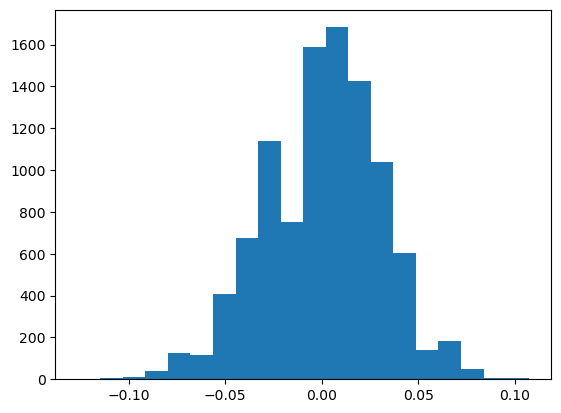

In [77]:
plt.hist(per_res.null_distribution, bins=20)

In [80]:
per_res.statistic

0.02928351796848025

In [54]:
ks_2samp(df_joined_ar.loc[pos_idx, metric + "_percentile"],df_joined_ar.loc[neg_idx, metric + "_percentile"]) 

KstestResult(statistic=0.025423645027979357, pvalue=0.7705396309227777, statistic_location=0.0, statistic_sign=1)

<Axes: >

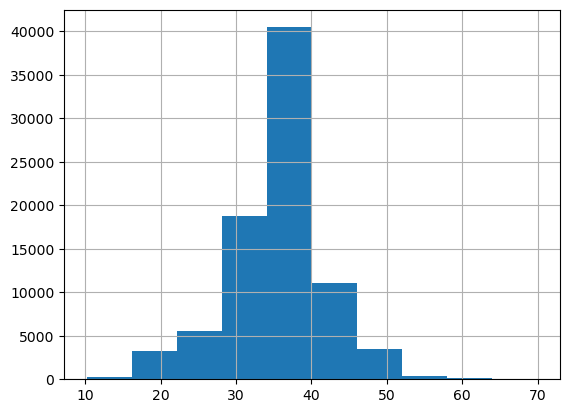

In [87]:
df_joined_ar["precip_sum"].hist()

In [89]:
1.5 * 25.4

38.099999999999994

(array([23843., 16524., 14194., 14700., 14242.]),
 array([0., 1., 2., 3., 4., 5.]),
 <BarContainer object of 5 artists>)

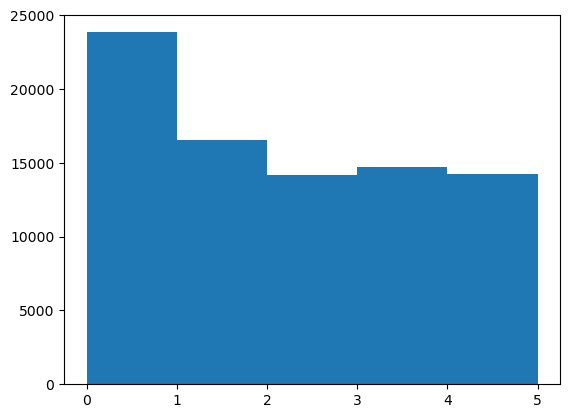

In [17]:
plt.hist(np.where(ranks==2)[1], np.arange(6))

In [18]:
ks_2samp(np.where(ranks==2)[1], np.where(ranks==0)[1])

KstestResult(statistic=0.22929715100056286, pvalue=0.0, statistic_location=1, statistic_sign=1)

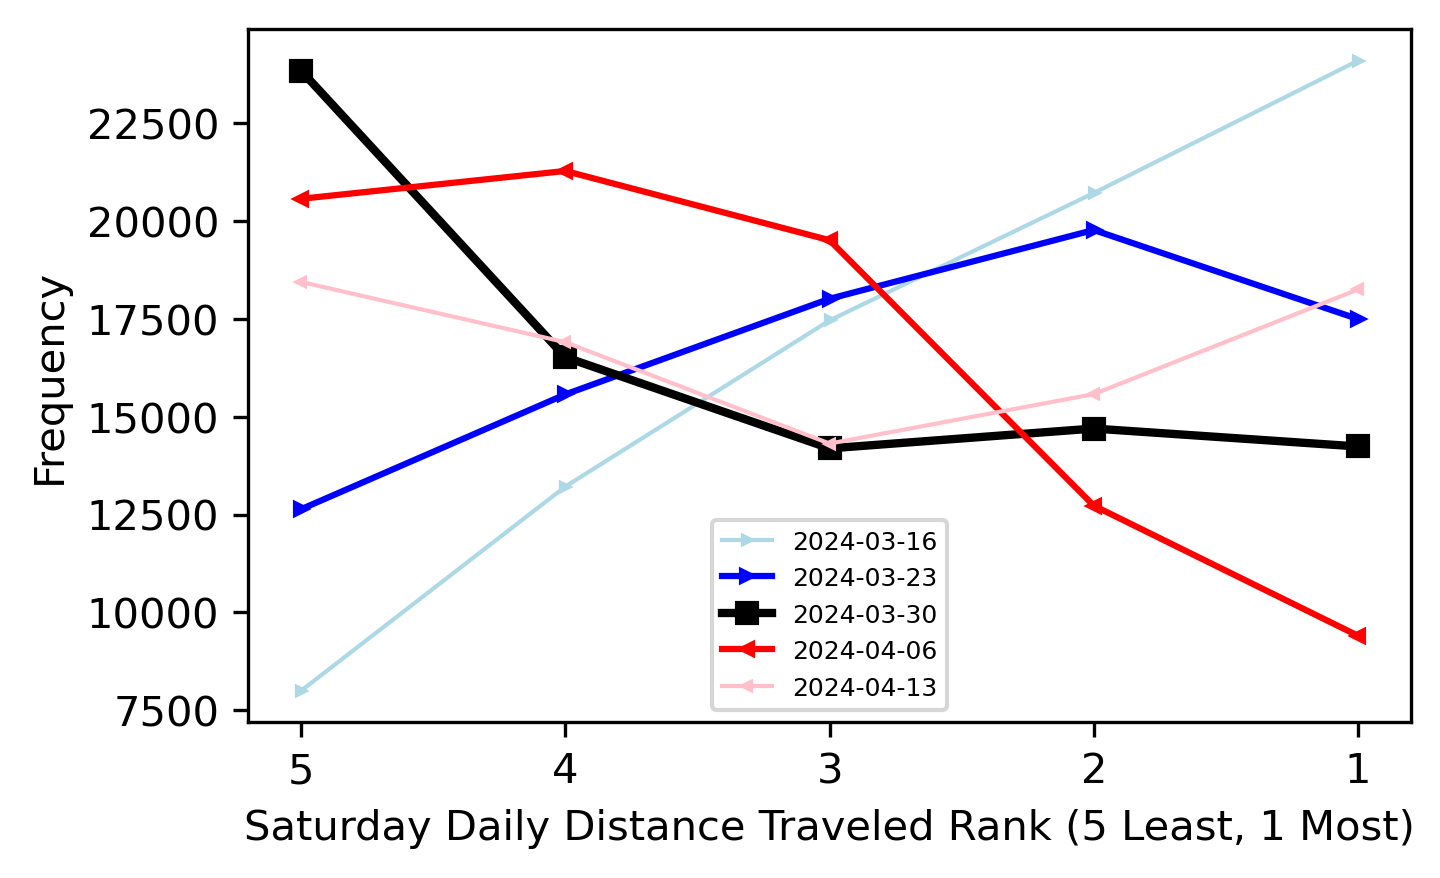

In [19]:
plt.figure(figsize=(5, 3), dpi=300)
color = ["lightblue", "blue", "k", "red", "pink"]
marker = [">", ">", "s", "<", "<"]
marker_size = [2, 3, 5, 3, 2]
linewidth = [1, 1.5, 2, 1.5, 1]
bins = np.arange(1, 7)
for i in range(ranks.shape[1]):
    hist_out, _ = np.histogram(np.where(ranks == i)[1] + 1, bins=bins)
    plt.plot(bins[:-1], hist_out, 
             color=color[i], 
             marker=marker[i], 
             ms=marker_size[i], 
             lw=linewidth[i],
             label=sat_dates[i])
plt.xticks(np.arange(1, 6), np.arange(1, 6)[::-1])
plt.xlabel("Saturday Daily Distance Traveled Rank (5 Least, 1 Most)")
plt.ylabel("Frequency")
plt.legend(fontsize=6)
plt.savefig("travel_freq.png", dpi=300, bbox_inches="tight")
plt.savefig("travel_freq.pdf", dpi=300, bbox_inches="tight")

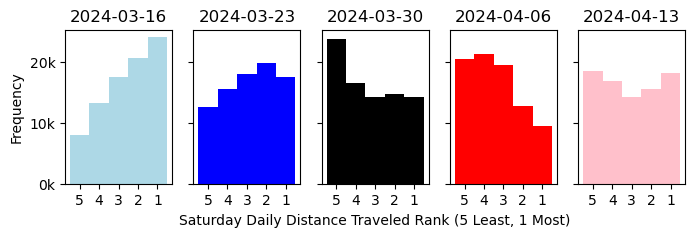

In [45]:
fig, axes = plt.subplots(1, 5, sharey=True, figsize=(8, 2))
color = ["lightblue", "blue", "k", "red", "pink"]
marker = [">", ">", "s", "<", "<"]
marker_size = [2, 3, 5, 3, 2]
linewidth = [1, 1.5, 2, 1.5, 1]
bins = np.arange(1, 7)
for i in range(ranks.shape[1]):
    hist_out, _ = np.histogram(np.where(ranks == i)[1] + 1, bins=bins)
    axes[i].bar(bins[:-1], hist_out, 1,
             color=color[i], 
             lw=linewidth[i],
             label=sat_dates[i])
    axes[i].set_xticks(np.arange(1, 6), np.arange(1, 6)[::-1])
    axes[i].set_title(sat_dates[i])
axes[2].set_xlabel("Saturday Daily Distance Traveled Rank (5 Least, 1 Most)")
axes[0].set_ylabel("Frequency")
formatter = ticker.FuncFormatter(lambda x, pos: f'{int(x / 1000)}k')
axes[0].yaxis.set_major_formatter(formatter)
plt.savefig("travel_freq_hist.png", dpi=300, bbox_inches="tight")
plt.savefig("travel_freq_hist.pdf", dpi=300, bbox_inches="tight")

## Maps

In [24]:
zip_counts = home_loc_df.groupby("zipcode").count()
zip_traces = pd.DataFrame(0.0, index=zip_counts.index, columns=[metric + "_percentile"])
for zip_code in zip_counts.index:
    zip_traces.loc[zip_code] = np.mean(df_joined_ar.loc[df_joined_ar["zipcode"] == zip_code, metric + "_percentile"], axis=0)

In [28]:
zip_index = np.array([int(np.where(zip == zip_codes)[0][0]) for zip in zip_counts.index])

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


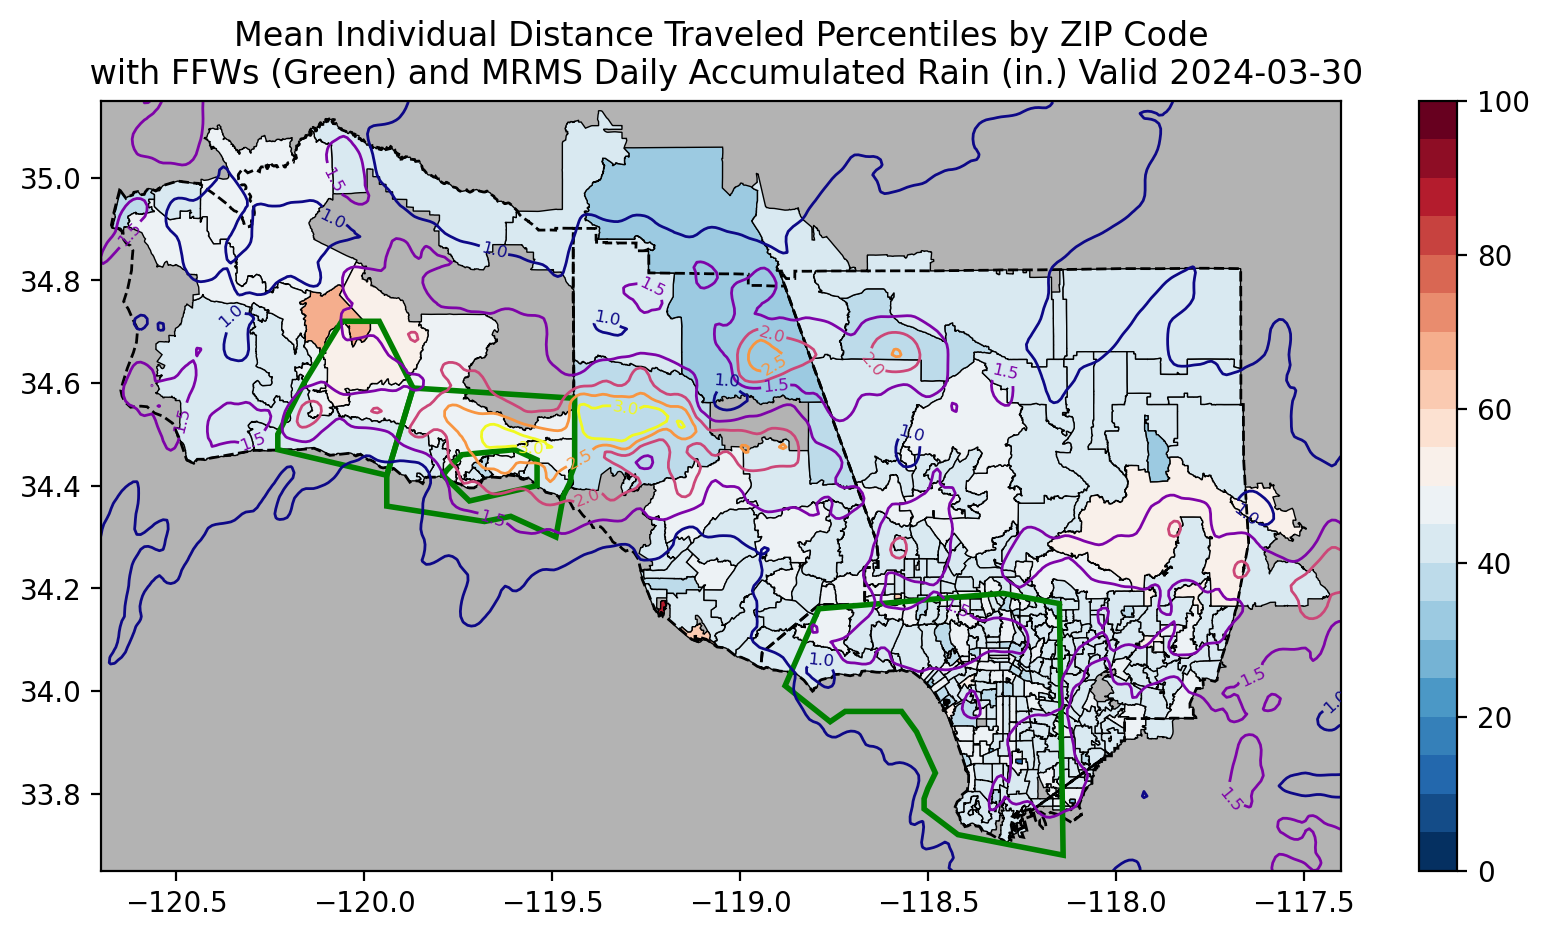

In [29]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r", 20)
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)

for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc[metric + "_percentile"]), ec='k', lw=0.5)
for county_shape in county_shapes:
    county_coords = np.array(county_shape.points).T
    plt.fill(county_coords[0], county_coords[1], facecolor="none", edgecolor="k", linestyle="--")
plt.xlim(-120.7, -117.4)
plt.ylim(33.65, 35.15)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat.png", bbox_inches="tight", dpi=300)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


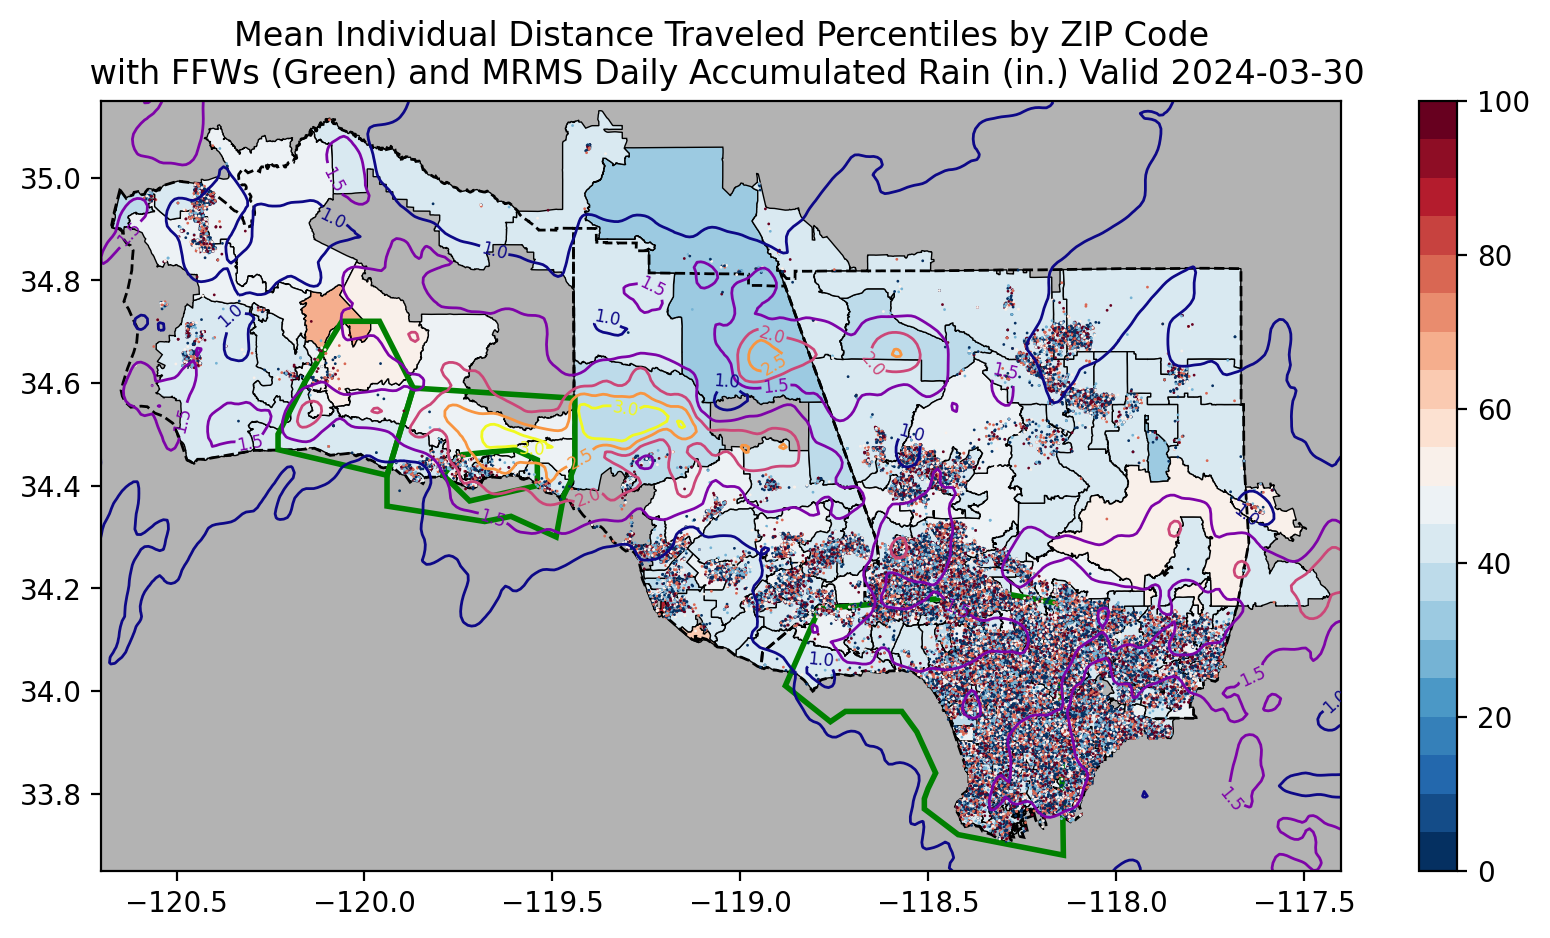

In [309]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r", 20)
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)

for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc[metric + "_percentile"]), ec='k', lw=0.5)
for county_shape in county_shapes:
    county_coords = np.array(county_shape.points).T
    plt.fill(county_coords[0], county_coords[1], facecolor="none", edgecolor="k", linestyle="--")
plt.xlim(-120.7, -117.4)
plt.ylim(33.65, 35.15)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.scatter(df_joined_ar["lng_home"], df_joined_ar["lat_home"], 1, df_joined_ar[metric + "_percentile"], cmap=cmap, vmin=0, vmax=100, ec="none")
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat_users.png", bbox_inches="tight", dpi=300)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


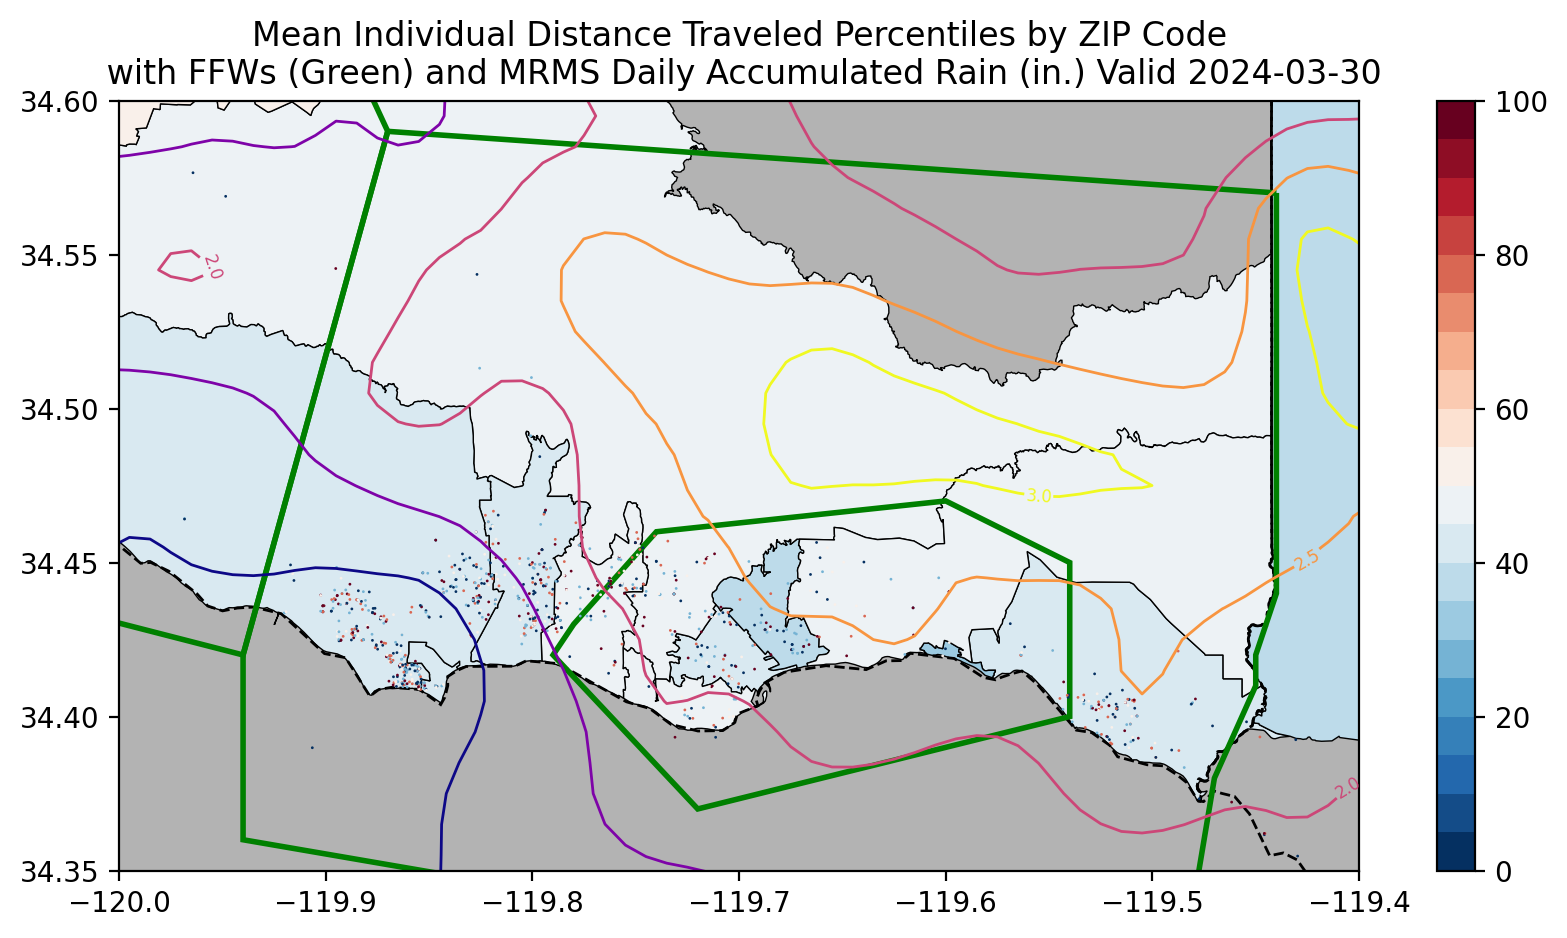

In [312]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r", 20)
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)

for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc[metric + "_percentile"]), ec='k', lw=0.5)
for county_shape in county_shapes:
    county_coords = np.array(county_shape.points).T
    plt.fill(county_coords[0], county_coords[1], facecolor="none", edgecolor="k", linestyle="--")
plt.xlim(-120.0, -119.4)
plt.ylim(34.35, 34.6)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.scatter(df_joined_ar["lng_home"], df_joined_ar["lat_home"], 1, df_joined_ar[metric + "_percentile"], cmap=cmap, vmin=0, vmax=100, ec="none")
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat_users_sb.png", bbox_inches="tight", dpi=300)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


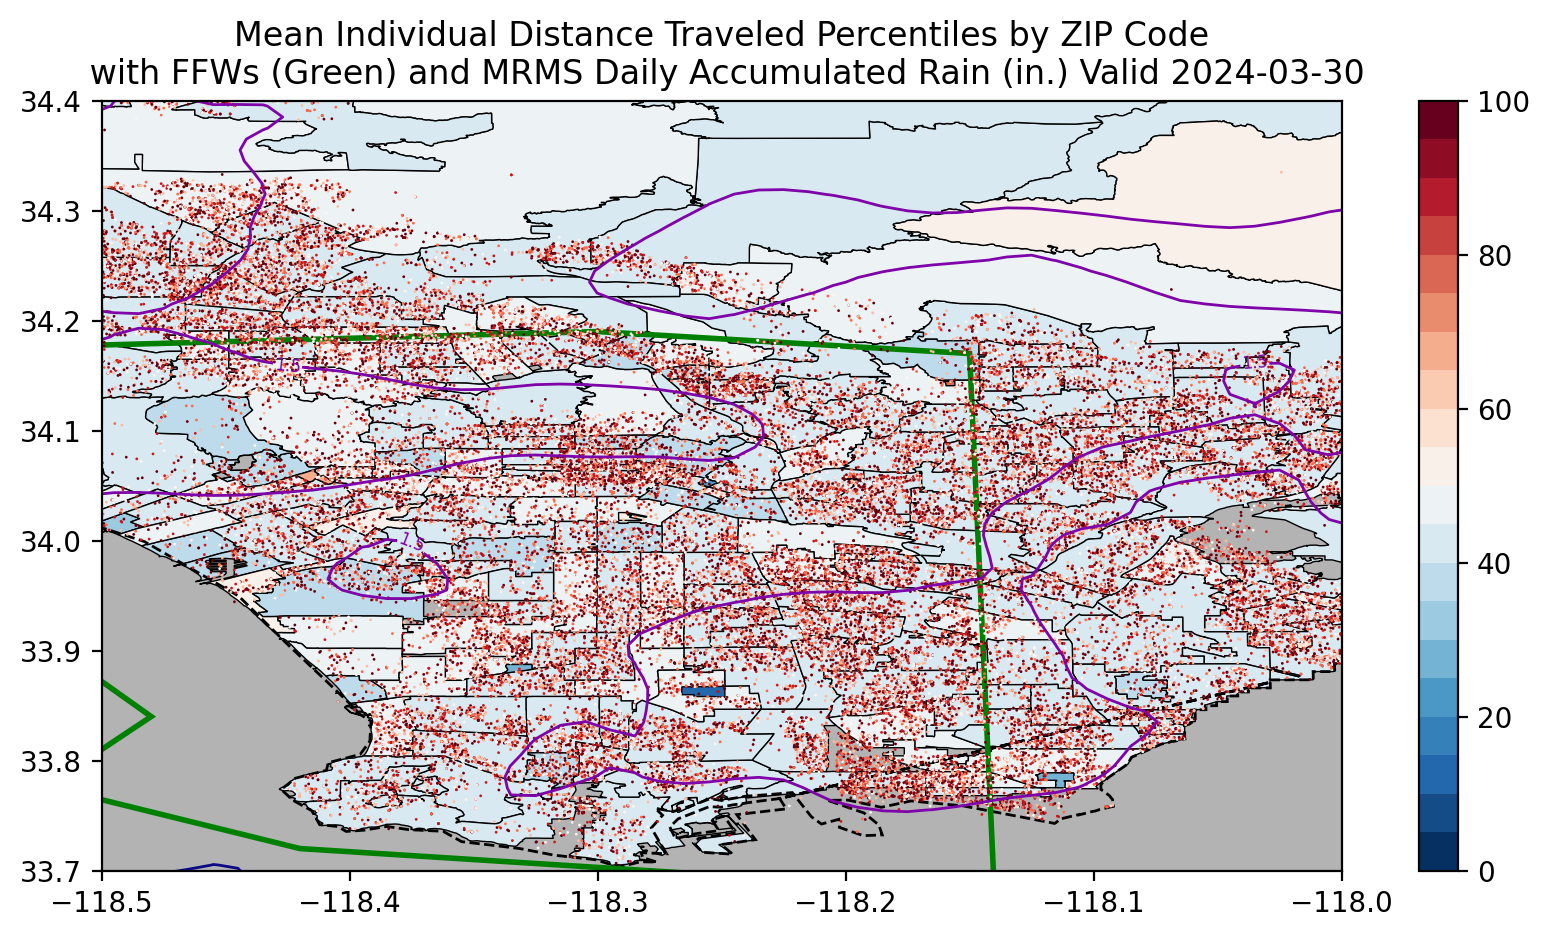

In [319]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r", 20)
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)

for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc[metric + "_percentile"]), ec='k', lw=0.5)
for county_shape in county_shapes:
    county_coords = np.array(county_shape.points).T
    plt.fill(county_coords[0], county_coords[1], facecolor="none", edgecolor="k", linestyle="--")
plt.xlim(-118.5, -118.0)
plt.ylim(33.7, 34.4)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.scatter(df_joined_ar["lng_home"], df_joined_ar["lat_home"], 1, df_joined_ar[metric + "_percentile"], cmap="Reds_r", vmin=0, vmax=100, ec="none")
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat_users_la.png", bbox_inches="tight", dpi=300)

In [113]:
from awips.dataaccess import DataAccessLayer
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import numpy as np
from shapely.geometry import Polygon

# 1. Connect to Unidata's public EDEX server
DataAccessLayer.changeEDEXHost("edex-cloud.unidata.ucar.edu")

# 2. Define a geographic bounding box (e.g., Colorado Rockies)
bbox = Polygon([(-120.7, 33.65), (-117.4, 33.65), (-117.4, 35.15), (-120.7,35.15)])
#bbox = Polygon([(-109, 37), (-102, 37), (-102, 41), (-109, 41)])

# 3. Create a request for AWIPS topography (topo) data
request = DataAccessLayer.newDataRequest("grid")
request.setLocationNames("topo")
request.setParameters("All")
request.setEnvelope(bbox)

# 4. Fetch the topography grid data
response = DataAccessLayer.getGridData(request)
print(response)
grid_data = response[0]

# Extract the raw elevation matrix and grid boundaries
elevation = grid_data.getRawData()
lon_grid, lat_grid = grid_data.getLatLonCoords()

# Define spatial extent for the imshow mapping [xmin, xmax, ymin, ymax]
extent = [lon_grid.min(), lon_grid.max(), lat_grid.min(), lat_grid.max()]

# 5. Compute the hillshade shadow effect using Matplotlib LightSource
# 'azimuth' is the compass direction of the light; 'altdeg' is the sun's angle above the horizon
ls = LightSource(azimuth=315, altdeg=45)

# Calculate the shadow intensity array
# vert_exag accentuates the mountains to create deeper, more defined shadows
shadow_effect = ls.hillshade(elevation, vert_exag=2.0)

# 6. Initialize Plot
fig, ax = plt.subplots(
    figsize=(12, 9), 
    subplot_kw={'projection': ccrs.PlateCarree()}
)
ax.set_extent(extent, crs=ccrs.PlateCarree())

# 7. Render the terrain shadow effect as an underlay
# Using a grayscale colormap ('gray') turns the hillshade into realistic shadows
ax.imshow(
    shadow_effect, 
    extent=extent, 
    cmap='gray', 
    origin='lower', 
    transform=ccrs.PlateCarree(),
    alpha=0.85
)

[]


IndexError: list index out of range